In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emcee
import corner

from scipy.optimize import minimize
from scipy.stats import gaussian_kde

from sklearn.utils import resample

from astropy.coordinates import SkyCoord
from astropy.visualization.wcsaxes import SphericalCircle
import astropy.units as u

import time
import tqdm as tqdm
from multiprocessing import Pool
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(123)

[ 0.00142689 -0.04548918  0.36606032  1.        ]


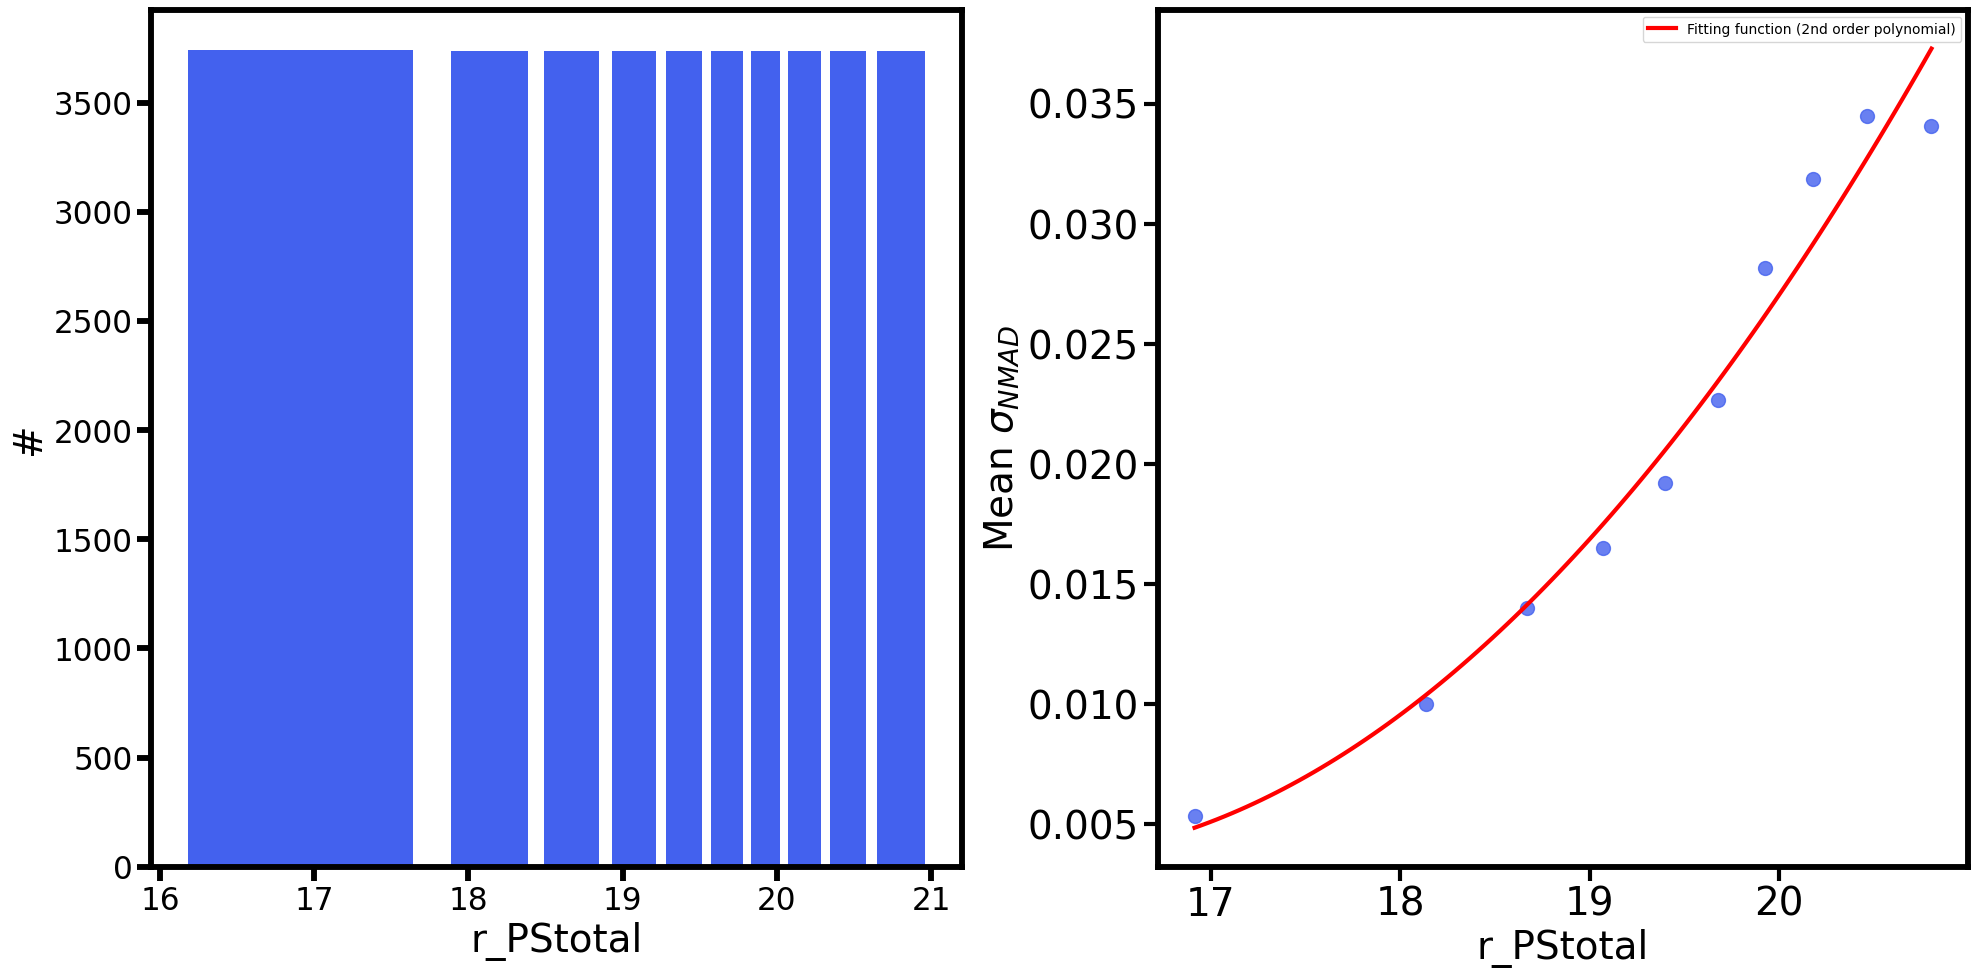

In [2]:
from galaxy_cluster_membership import *

In [3]:
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import rc, rcParams
f = 0.8

fontsize = 35 * f
labelsize = 20 * f

rc("xtick", labelsize=fontsize * f)
rc("ytick", labelsize=fontsize * f)
rcParams["axes.linewidth"] = 5.3 * f
rcParams["xtick.major.width"] = 5.3 * f
rcParams["xtick.minor.width"] = 5.3 * f
rcParams["ytick.major.width"] = 5.3 * f
rcParams["ytick.minor.width"] = 5.3 * f
rcParams["xtick.major.size"] = 12.5 * f
rcParams["xtick.minor.size"] = 6.5 * f
rcParams["ytick.major.size"] = 12.5 * f
rcParams["ytick.minor.size"] = 6.5 * f

font = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 50 * f,
        }


cm1 = plt.cm.get_cmap('jet')
cm2 = plt.cm.get_cmap('rainbow')
cm3 = plt.cm.get_cmap('gnuplot2')
cm4 = plt.cm.get_cmap('Pastel2')
cm5 = plt.cm.get_cmap('Set3')
cm6 = plt.cm.get_cmap('gist_rainbow')

color_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
colors1 = [cm1(value) for value in color_values]
colors2 = [cm2(value) for value in color_values]
colors3 = [cm3(value) for value in color_values]
colors4 = [cm4(value) for value in color_values]
colors5 = [cm5(value) for value in color_values]
colors6 = [cm6(value) for value in color_values]

### Load data

In [4]:
i_mock = 49

t = pd.read_csv("tables/testing-on-mocks/membership-mock-clusters/23-07-2025/cluster-mock_{}_membership.csv".format(i_mock))
members = t["phot_member"] == 1
ras = np.array(t["RA"][members]) #deg
decs = np.array(t["DEC"][members]) #deg
zp = np.array(t["z_phot_pdfs_mock"][members]) #uso os photo-zs que vem da "clonagem" de galáxias do training set
zs = np.array(t["z_app"][members]) 


x0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/ra0_list.npy")[i_mock]
y0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/dec0_list.npy")[i_mock]
r200_deg = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_deg_list.npy")[i_mock]
r200_mpc = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_mpc_list.npy")[i_mock]
m200 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/m200_list.npy")[i_mock]
z_cluster = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/z_cluster_list.npy")[i_mock]


side = min(max(ras) - min(ras), max(decs) - min(decs))
all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})
# x0 = np.mean(ras)
# y0 = np.mean(decs)

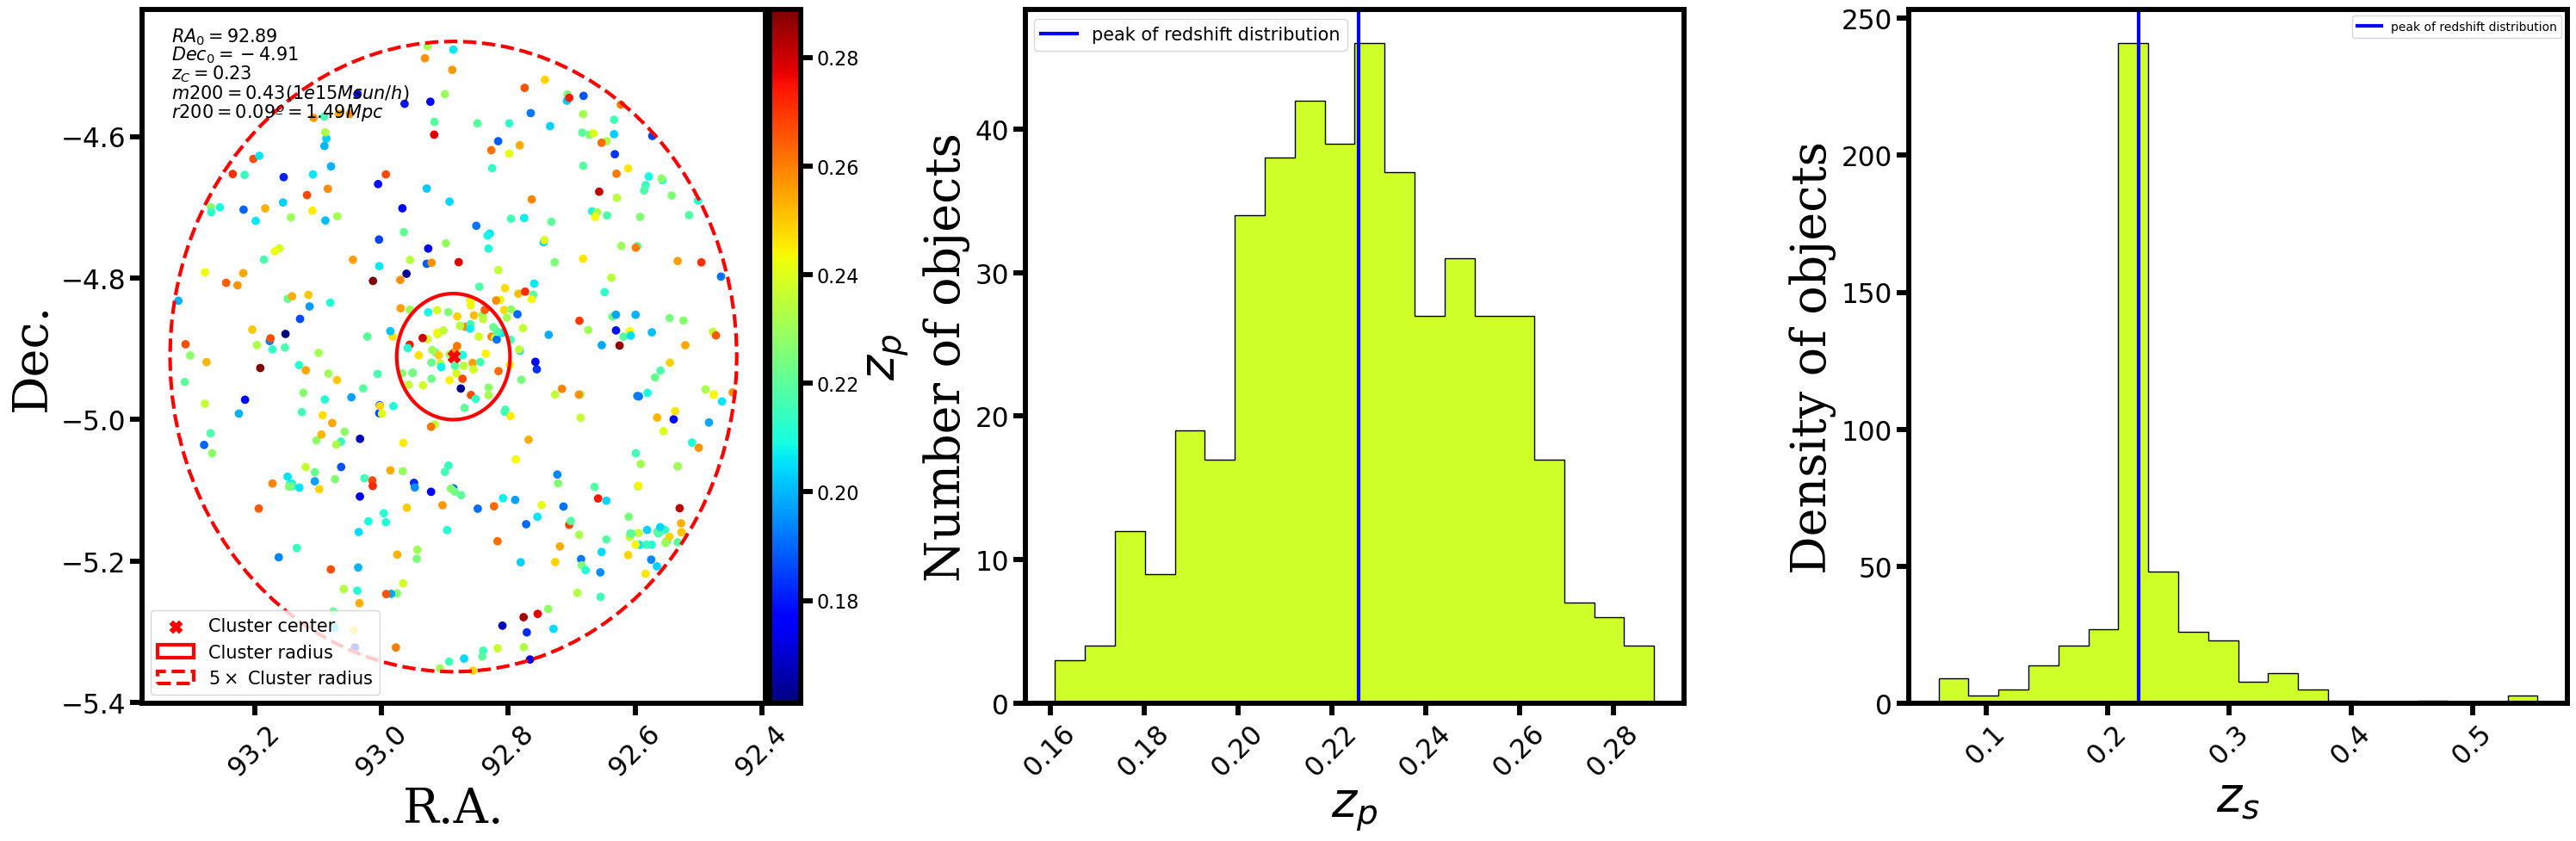

In [5]:
z_bins = 20
fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(30, 10))
ax1 = axs[0]
ax2 = axs[1]
ax3 = axs[2]
# ax4 = axs[1, 1]

#Plot spatial distribution
sc = ax1.scatter(ras, decs, c=zp, cmap=cm1)
ax1.scatter(x0, y0, marker="X", s=100, color="red", label="Cluster center")

ax1.set_xlabel("R.A.", fontdict=font)
ax1.set_ylabel("Dec.", fontdict=font)
ax1.tick_params(axis='x', rotation=45)

max_radius = 5
ax1.text(x0+max_radius*r200_deg, y0+max_radius*r200_deg, s=r"$RA_0 = {:.2f}$".format(x0), fontsize=15)
ax1.text(x0+max_radius*r200_deg, y0+(max_radius-0.3)*r200_deg, s=r"$Dec_0 = {:.2f}$".format(y0), fontsize=15)
ax1.text(x0+max_radius*r200_deg, y0+(max_radius-0.6)*r200_deg, s=r"$z_C = {:.2f}$".format(z_cluster), fontsize=15)
ax1.text(x0+max_radius*r200_deg, y0+(max_radius-0.9)*r200_deg, s=r"$m200 = {:.2f} (1e15 Msun/h)$".format(m200/1e15), fontsize=15)
ax1.text(x0+max_radius*r200_deg, y0+(max_radius-1.2)*r200_deg, s=r"$r200 = {:.2f}º = {:.2f} Mpc$".format(r200_deg, r200_mpc), fontsize=15)

c0 = SkyCoord(ra=x0, dec=y0, frame='icrs', unit='deg')
r1 = SphericalCircle(c0, r200_deg*u.deg, resolution=100, vertex_unit='deg', 
            lw=3, label="Cluster radius", edgecolor="red", facecolor="None")
ax1.add_patch(r1)
r2 = SphericalCircle(c0, 5*r200_deg*u.deg, resolution=100, vertex_unit='deg', 
            lw=3, label=r"$5 \times$ Cluster radius", edgecolor="red", facecolor="None", ls='--')
ax1.add_patch(r2)

divider = make_axes_locatable(ax1)
cax1 = divider.append_axes('right', size='5%', pad=0.05)
cbar = fig.colorbar(sc, cax=cax1, orientation='vertical')
cbar.set_label(label=r"$z_p$", fontdict=font)
cbar.ax.tick_params(labelsize=labelsize)

ax1.invert_xaxis()
ax1.legend(fontsize=15)


#Distribution of spec-zs of cluster galaxies
hist = ax3.hist(zs, bins=z_bins, color=colors1[5], histtype='stepfilled', edgecolor='k', 
         range=[zs.min(), zs.max()])[0]
ax3.set_xlabel("z_spec", fontdict=font)
ax3.set_ylabel("Number of objects", fontdict=font)
ax3.tick_params(axis='x', rotation=45)

ax3.axvline(z_cluster, color="blue", lw=3, label="peak of redshift distribution")
ax3.set_xlabel(r"$z_s$", fontdict=font)
ax3.set_ylabel("Density of objects", fontdict=font)
ax3.tick_params(axis='x', rotation=45)
ax3.legend(fontsize=10)


#Distribution of photo-zs of cluster galaxies
ax2.hist(zp, bins=z_bins, color=colors1[5], histtype='stepfilled', edgecolor='k')[2]
ax2.set_xlabel(r"$z_p$", fontdict=font)
ax2.set_ylabel("Number of objects", fontdict=font)
ax2.axvline(z_cluster, color="blue", lw=3, label="peak of redshift distribution")
ax2.tick_params(axis='x', rotation=45)
ax2.legend(fontsize=15)

fig.tight_layout(pad=1.0)

Text(0, 0.5, 'DEC')

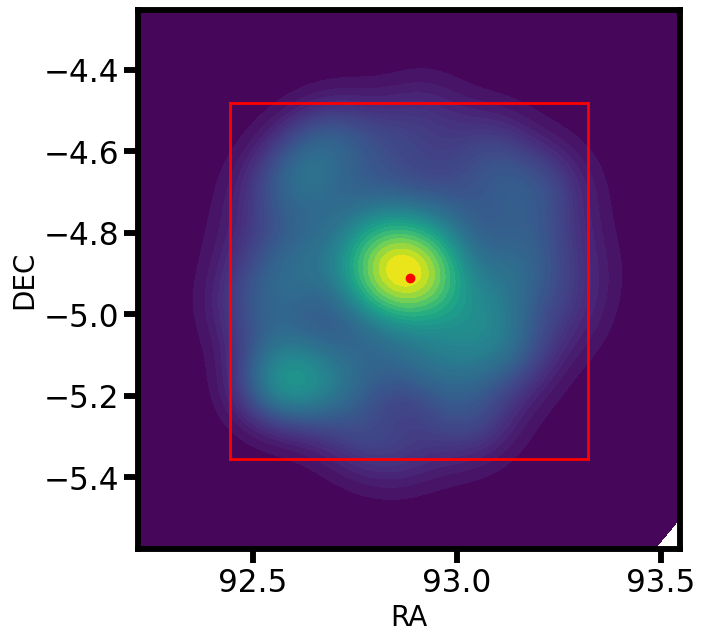

In [6]:
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111)
# plt.scatter(all_galaxies['RAs'], all_galaxies['DECs'], alpha=0.5)

sns.kdeplot(x=ras, y=decs, fill=True, thresh=0, cmap="viridis", levels=50)

# ax.scatter(np.median(boot_results["x_c"]), np.median(boot_results["y_c"]), marker="o", color="k")

# ax.scatter(97.69, -7.46, marker="o", color="k")

ax.plot([min(ras), min(ras)], [min(decs), min(decs)+side], color="red", lw=2.0, label="side")
ax.plot([max(ras), max(ras)], [min(decs), min(decs)+side], color="red", lw=2.0)
ax.plot([min(ras), max(ras)], [min(decs), min(decs)], color="red", lw=2.0)
ax.plot([min(ras), max(ras)], [min(decs)+side, min(decs)+side], color="red", lw=2.0)

ax.scatter(x0, y0, color='red')

ax.set_xlabel('RA', fontsize=20)
ax.set_ylabel('DEC', fontsize=20)

In [7]:
#Distribuição cumulativa observada
Rp = clustercentric_distance(ras, decs, x0, y0)
Hz, Rcz = np.histogram(Rp, bins=100, density=True)
dR = Rcz[1] - Rcz[0]
Fz = np.cumsum(Hz)*dR
R = Rcz[1:]

In [8]:
def Sersic_density(R, dR, params):

    Sigma0, R0, alpha, Sigma_field = params

    Sigma_c = np.exp(-(R/R0)**alpha) * Sigma0

    cum_f = np.pi * Sigma_field * R**2
    #Polar integral of Sigma_c to obtain the cumulative density profile
    cum_c = 2*np.pi*np.array([np.sum(Sigma_c[R < R[i]] * R[R < R[i]] * dR) for i in range(len(R))])
    cum_dens = cum_f + cum_c

    return cum_dens

### Trying some mcmc trick
The ideia is to use mcmc to guess the initial parameters and then minimize the chi²

In [9]:
def log_likelihood(params, R, dR, data): 
    
    model_density = Sersic_density(R, dR, params)
    residuals = data - model_density
    sigma = np.sqrt(1/len(data) * (residuals)**2)
    
    # Assuming Gaussian noise, the log likelihood is proportional to the square of residuals
    return -0.5 * np.sum(residuals**2/sigma**2 + np.log(2 * np.pi * sigma**2)) * 0.2


# Define prior distributions (simple uniform priors in this case)
def log_prior(params):
    Sigma0, R0, alpha, Sigma_field = params
    
    if 0 < Sigma0 < 100 and 0 < R0 < 10*r200_deg and 0 < alpha < 10 and 0 < Sigma_field < 100:
        return 0.0  # log(1) = 0, uniform prior
    return -np.inf  # log(0) = -inf, to reject parameters outside these ranges
    

def log_probability(params, R, dR, data):
    lp = log_prior(params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params, R, dR, data)


def run_mcmc(nsteps, pos, log_probability, args, moves, multi_process=False):

    nwalkers, ndim = pos.shape

    if multi_process == False:
        sampler = emcee.EnsembleSampler(
            nwalkers, 
            ndim, 
            log_probability, 
            args=args,
            moves=moves
        )
        sampler.run_mcmc(pos, nsteps, progress=True);

    elif multi_process == True:
        with Pool(processes=nwalkers) as pool:
            sampler = emcee.EnsembleSampler(
                nwalkers,
                ndim,
                log_probability,
                args=args,
                pool=pool
                )
            
            start = time.time()

            sampler.run_mcmc(pos, nsteps, progress=True)
            
            end = time.time()
            multi_time = end - start
            print("Multiprocessing took {0:.1f} seconds".format(multi_time))

    return sampler

In [52]:
nsteps = 10000
nwalkers = 32
burn_in = 0.2

init = [1, r200_deg/2, 1, 0.5]
pos = init + 1e-4 * np.random.randn(nwalkers, len(init))

sampler = run_mcmc(nsteps, 
                    pos,
                    log_probability, 
                    args=(R, dR, Fz), 
                    moves=emcee.moves.StretchMove(),
                    multi_process=False)

labels = [r"$\Sigma_0$", r"$R_0$", r"$\alpha$", r"$\Sigma_{field}$"]

samples = sampler.get_chain()

#flat = flatten the chains across the ensample
#discard = discard the burn_in phase
#thin = "thins" the sample every N iterations (for instance 15)
flat_samples = sampler.get_chain(discard=int(nsteps*burn_in), thin=15, flat=True)
means = np.mean(flat_samples, axis=0)

100%|██████████| 10000/10000 [02:36<00:00, 63.99it/s]


30.966669773352095
0.06871117026671539
1.6352492702539725
2.3989703970097342


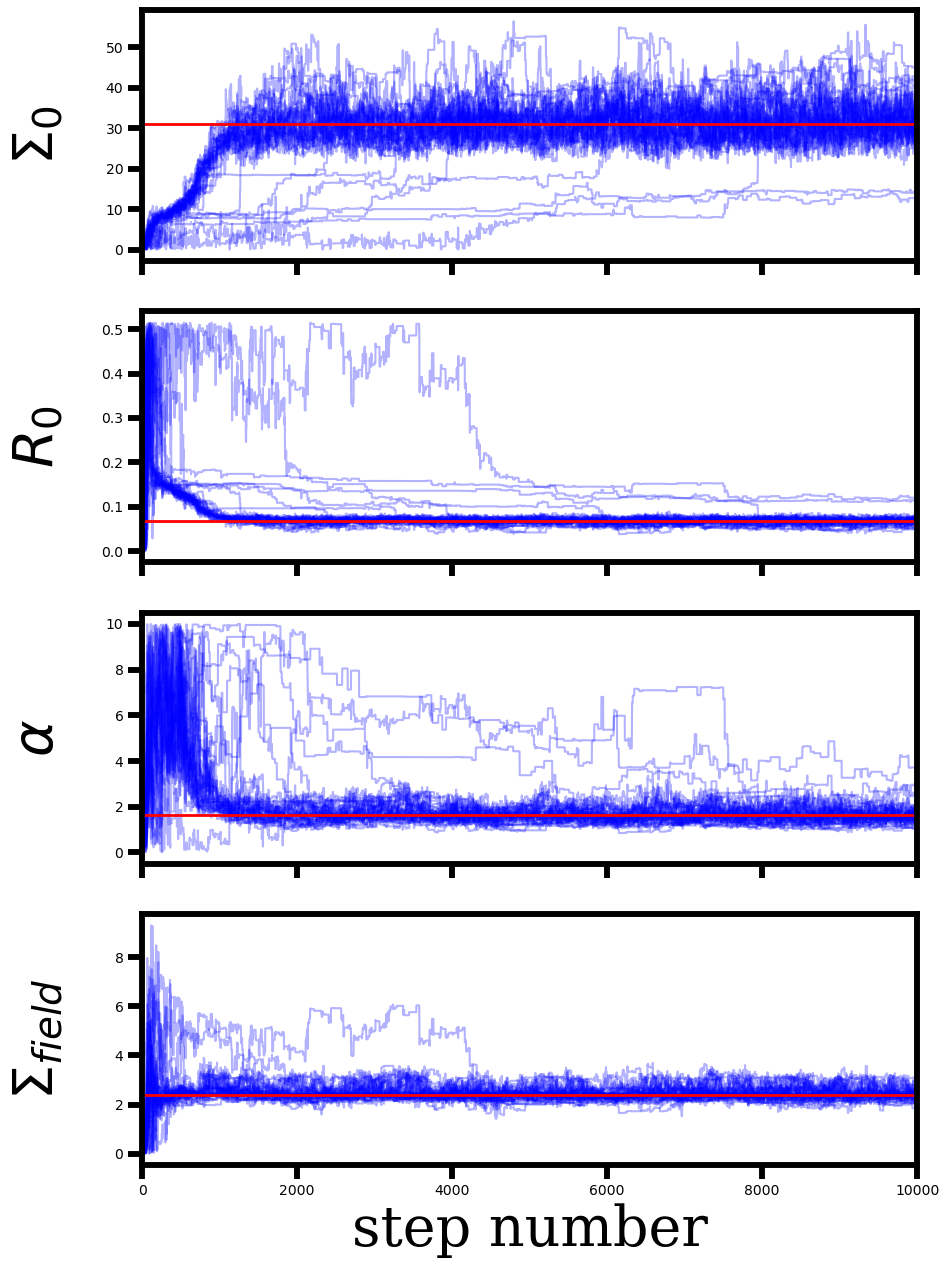

In [53]:
fig, axes = plt.subplots(4, figsize=(10, 15), sharex=True)

# Styling
rcParams["font.size"] = 10
rcParams["axes.labelsize"] = 10
rcParams["xtick.labelsize"] = 10
rcParams["ytick.labelsize"] = 10
for i in range(np.shape(pos)[1]):
    ax = axes[i]
    ax.plot(samples[:, :, i], "blue", alpha=0.3)
    ax.axhline(np.median(samples[int(burn_in*nsteps):, :, i]), color="red", lw=2.0)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontdict=font)
    ax.yaxis.set_label_coords(-0.1, 0.5)

    print(np.median(samples[int(burn_in*nsteps):, :, i]))

axes[-1].set_xlabel("step number", fontdict=font);

# plt.savefig("../figures/elliptical_profiles/SIS_SISell_NFW_NFWell_17-06-2025/trace_plot_mcmc_mock{}_model{}_{}iterations.png".format(i_mock, model, nsteps),
#                                      dpi='figure', format='png')


initial_guess = np.array([np.median(samples[int(burn_in*nsteps):, :, i]) for i in range(0, 4)])

### Minimizing chi² and doing bootstrap

In [10]:
def chi_squared(params, R, dR, observed_density):
    modeled_density = Sersic_density(R, dR, params)
    return np.sum((observed_density - modeled_density)**2)


def fit_cumulative(R, dR, data, init):
    
    bounds = [
        (0, 100), #Sigma0
        (0, 5.0*r200_deg), #R0
        (0, 5), #alpha
        (0, 20) #Sigma_field
    ]

    # init = [1, r200_deg/2, 1, 0.5]

    fit = minimize(chi_squared, init, args=(R, dR, data), method='Nelder-Mead', bounds=bounds)
    return fit


def bootstrap_fit(data, init, B=1000):
    estimates = np.zeros((B, 5))  # 5 parameters + chi2

    bounds = [
        (0, 100), #Sigma0
        (0, 5.0*r200_deg), #R0
        (0, 5), #alpha
        (0, 20) #Sigma_field
    ]

    for b in tqdm.tqdm(range(B)):
        resampled_data = resample(data)

        x = resampled_data["ras"] 
        y = resampled_data["decs"]

        Rp = clustercentric_distance(x, y, x0, y0)
        Hz, Rcz = np.histogram(Rp, bins=100, density=True)
        dR = Rcz[1] - Rcz[0]
        Fz = np.cumsum(Hz)*dR
        R = Rcz[1:]

        # try:
        fit_b = minimize(chi_squared, init, args=(R, dR, Fz), method='Nelder-Mead', bounds=bounds)
        # if fit_b.success:
        estimates[b, 0] = fit_b.x[0]  # Sigma0
        estimates[b, 1] = fit_b.x[1]  # R0
        estimates[b, 2] = fit_b.x[2]  # alpha
        estimates[b, 3] = fit_b.x[3]  # Sigma_field
        estimates[b, 4] = chi_squared(fit_b.x, R, dR, Fz)  # chi2
        # except:
        #     continue
    
    return pd.DataFrame(estimates, columns=["Sigma0", "R0", "alpha", "Sigma_field", "chi2"])

In [54]:
fit = fit_cumulative(R, dR, Fz, init=initial_guess)

print("Fitted parameters:")
for p_value, p_name in zip(fit.x, ["Sigma0", "R0", "alpha", "Sigma_field"]):
    print(p_name + " =", p_value)

print("R0/r200 = {:.3f}".format(fit.x[1]/r200_deg))

Fitted parameters:
Sigma0 = 32.44480303828305
R0 = 0.06658424420443847
alpha = 1.5621405557805126
Sigma_field = 2.420414067881439
R0/r200 = 1.292


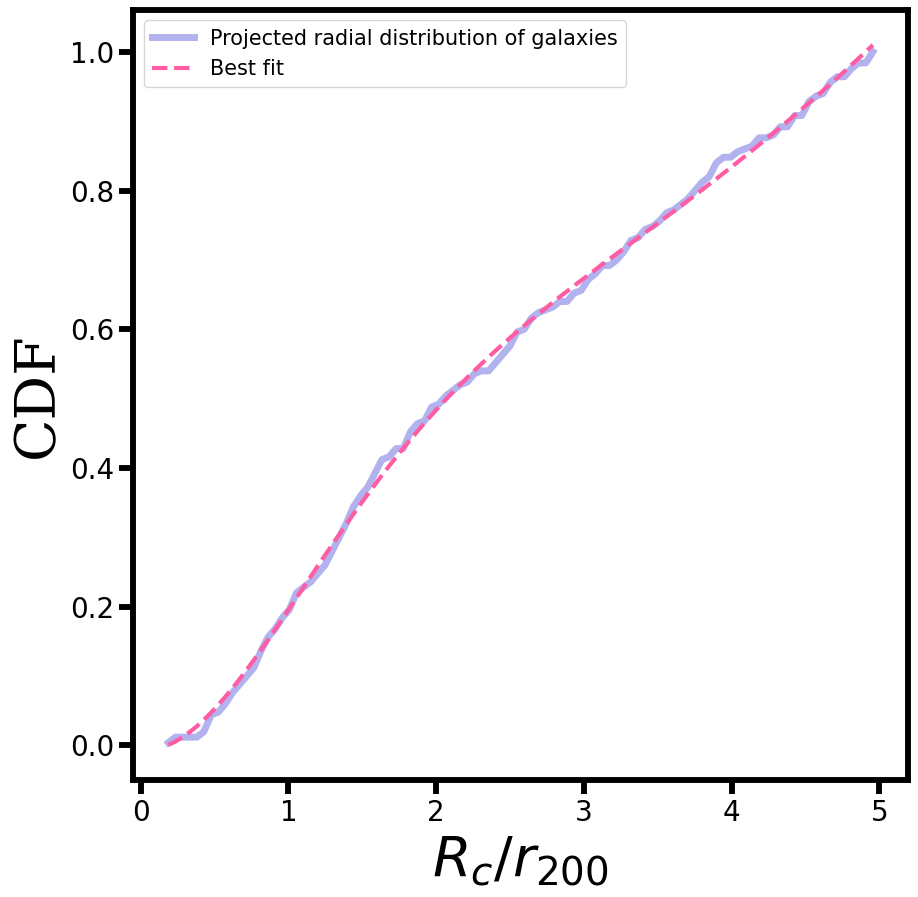

In [56]:
cum_dens = Sersic_density(R, dR, fit.x)

rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.plot(R/r200_deg, Fz, lw=5.0, c=colors3[1], label="Projected radial distribution of galaxies", alpha=0.3)
ax.plot(Rcz[1:]/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c=colors3[5])
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)
ax.legend(fontsize=15)

In [61]:
# Run bootstrap
t0 = time.time()
nboot = 1000
boot_results = bootstrap_fit(all_galaxies, init=fit.x, B=nboot)
print("Bootstrap time taken:", time.time() - t0)

100%|██████████| 1000/1000 [05:07<00:00,  3.25it/s]

Bootstrap time taken: 307.24158930778503


In [62]:
# Remove outliers
z = boot_results
for col in boot_results.columns:
    Q1 = boot_results[col].quantile(0.25)
    Q3 = boot_results[col].quantile(0.75)
    IQR = Q3 - Q1
    z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
    print("Remaining samples after outlier removal:", len(z))

boot_results_outliers_removed = z

Remaining samples after outlier removal: 904
Remaining samples after outlier removal: 904
Remaining samples after outlier removal: 855
Remaining samples after outlier removal: 840
Remaining samples after outlier removal: 819


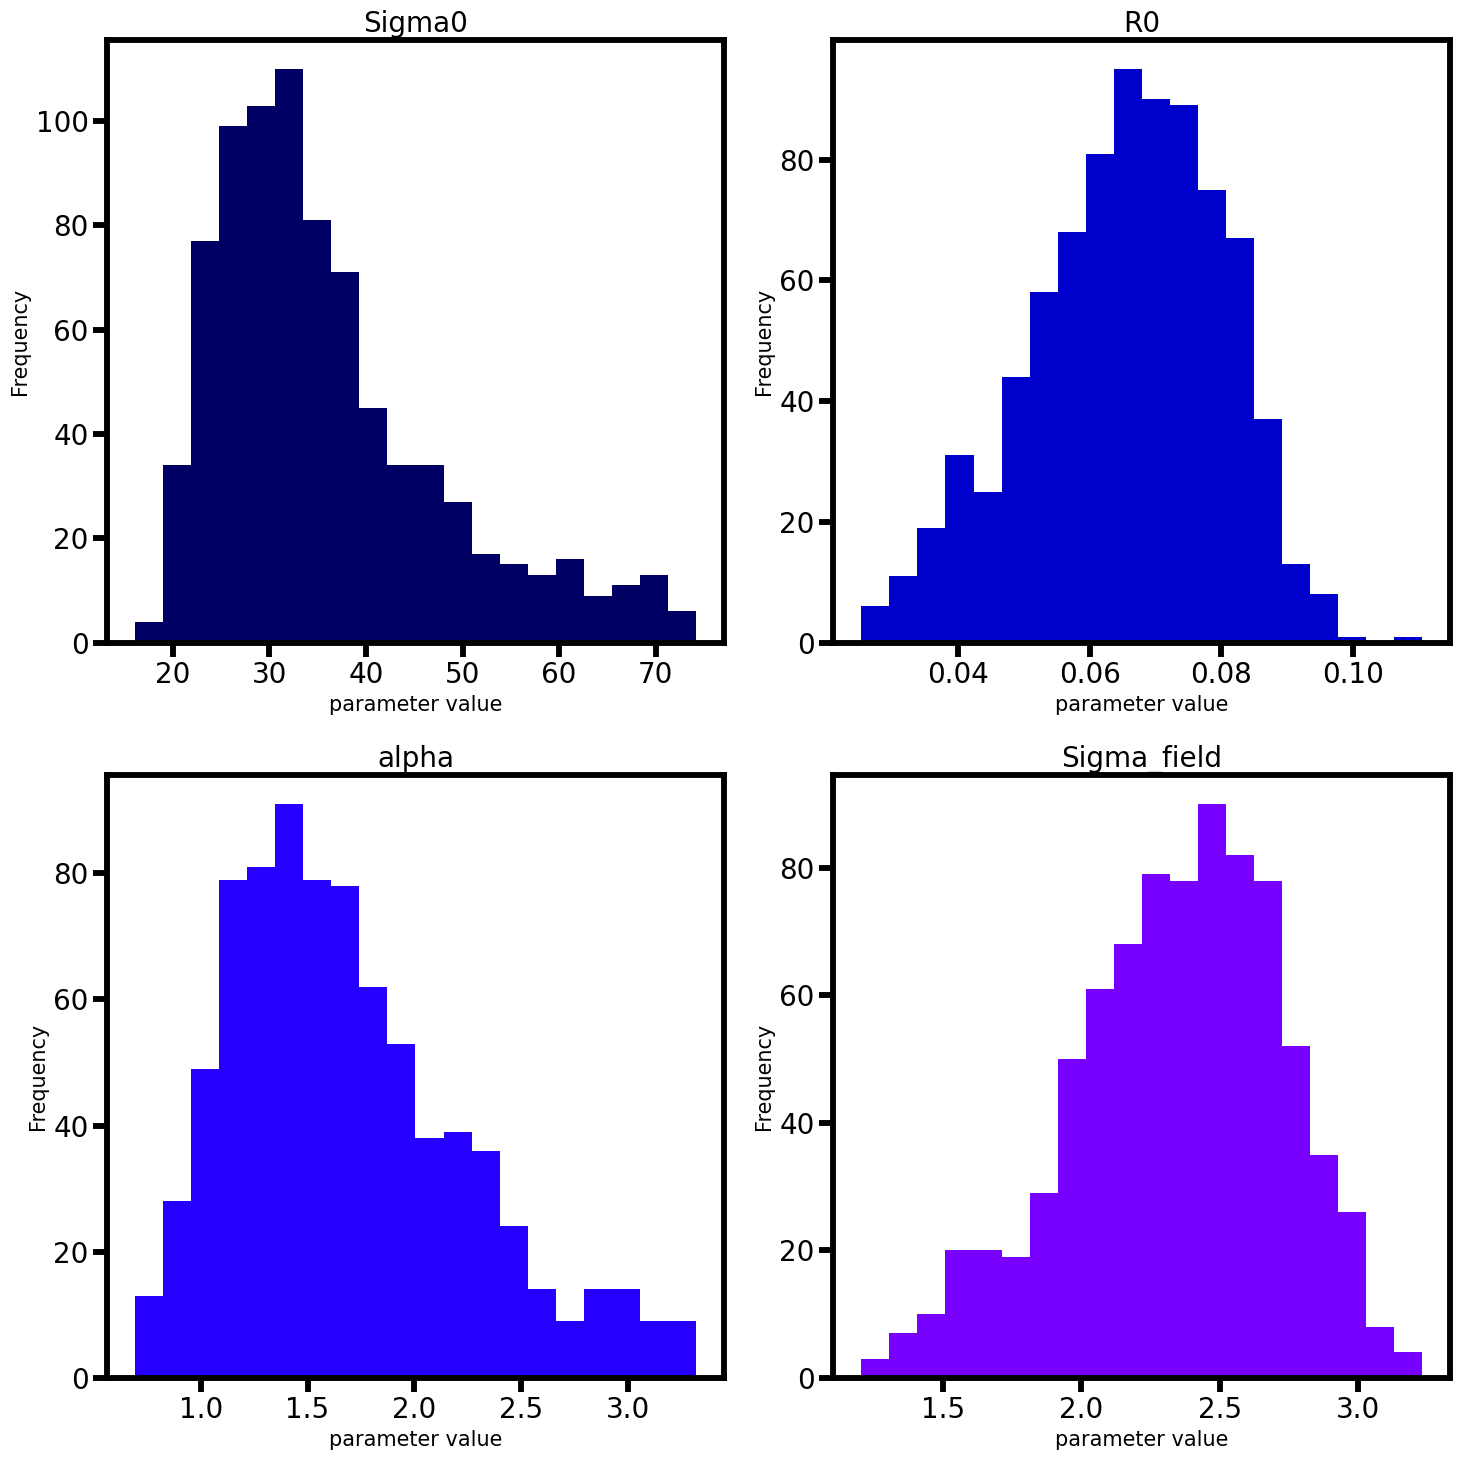

In [63]:
# Plot parameter distributions
plt.figure(figsize=(15, 15))
for i, col in enumerate(boot_results_outliers_removed.columns[:-1]):  # exclude chi2
    plt.subplot(2, 2, i+1)
    plt.hist(boot_results_outliers_removed[col], bins=20, color=colors3[i])
    plt.title(col, fontsize=20)
    plt.xlabel("parameter value", fontsize=15)
    plt.ylabel("Frequency", fontsize=15)
plt.tight_layout()

# plt.savefig("../figures/elliptical_profiles/boostrap_results/Sersic/boostrap_parameter_distribution_mock{}.pdf".format(i_mock), dpi='figure', format='pdf')

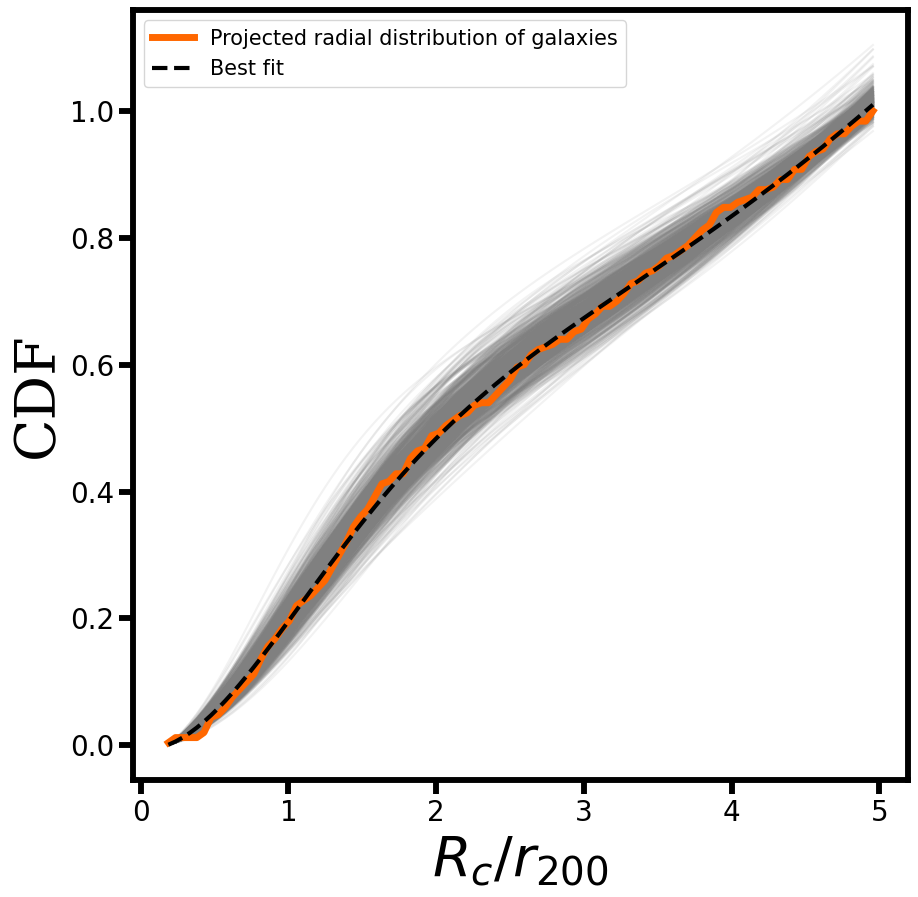

In [64]:
# cum_dens = Sersic_density(R, dR, fit.x)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   

ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)

for _, row in boot_results_outliers_removed.iterrows():
    params = row[:4].values
    cum_model = Sersic_density(R, dR, params)
    ax.plot(R/r200_deg, cum_model, color="gray", alpha=0.1)

ax.plot(R/r200_deg, Fz, lw=5.0, c="#ff6700", label="Projected radial distribution of galaxies", alpha=1.0)
ax.plot(R/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c="k")

ax.legend(fontsize=15)

### Running in a loop

COMPUTING FOR MOCK CLUSTER 49


100%|██████████| 10000/10000 [02:17<00:00, 72.62it/s]


18.546529671851275
0.040124853955475825
1.0646209360665655
1.3262401931675034
Fitted parameters:
Sigma0 = 19.608065859633037
R0 = 0.037859169400615664
alpha = 1.076638143622128
Sigma_field = 1.3545663012941678
R0/r200 = 0.425


100%|██████████| 1000/1000 [08:11<00:00,  2.04it/s]


Bootstrap time taken: 491.08484983444214
Remaining samples after outlier removal: 941
Remaining samples after outlier removal: 941
Remaining samples after outlier removal: 913
Remaining samples after outlier removal: 895
Remaining samples after outlier removal: 860


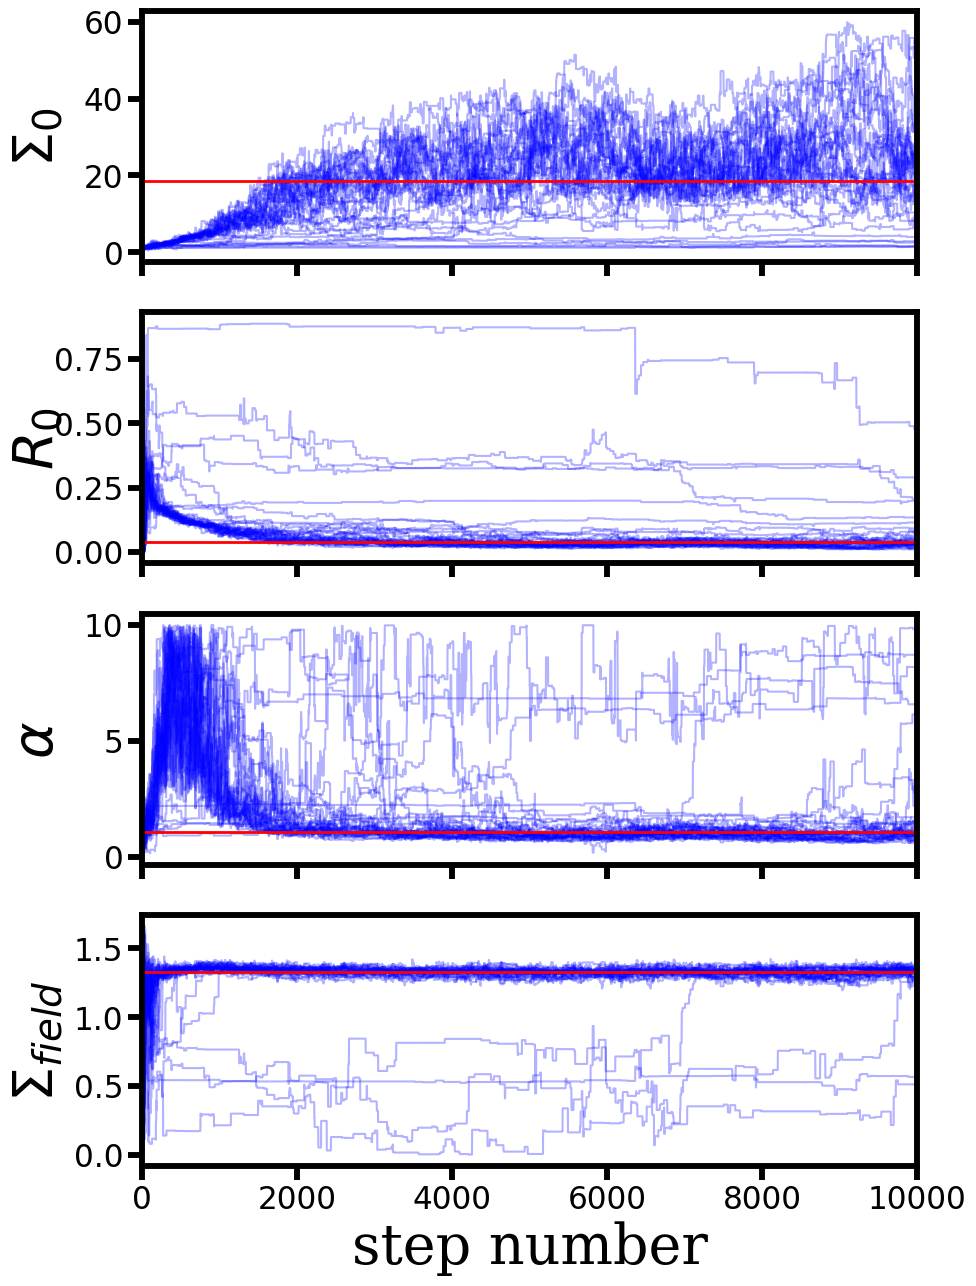

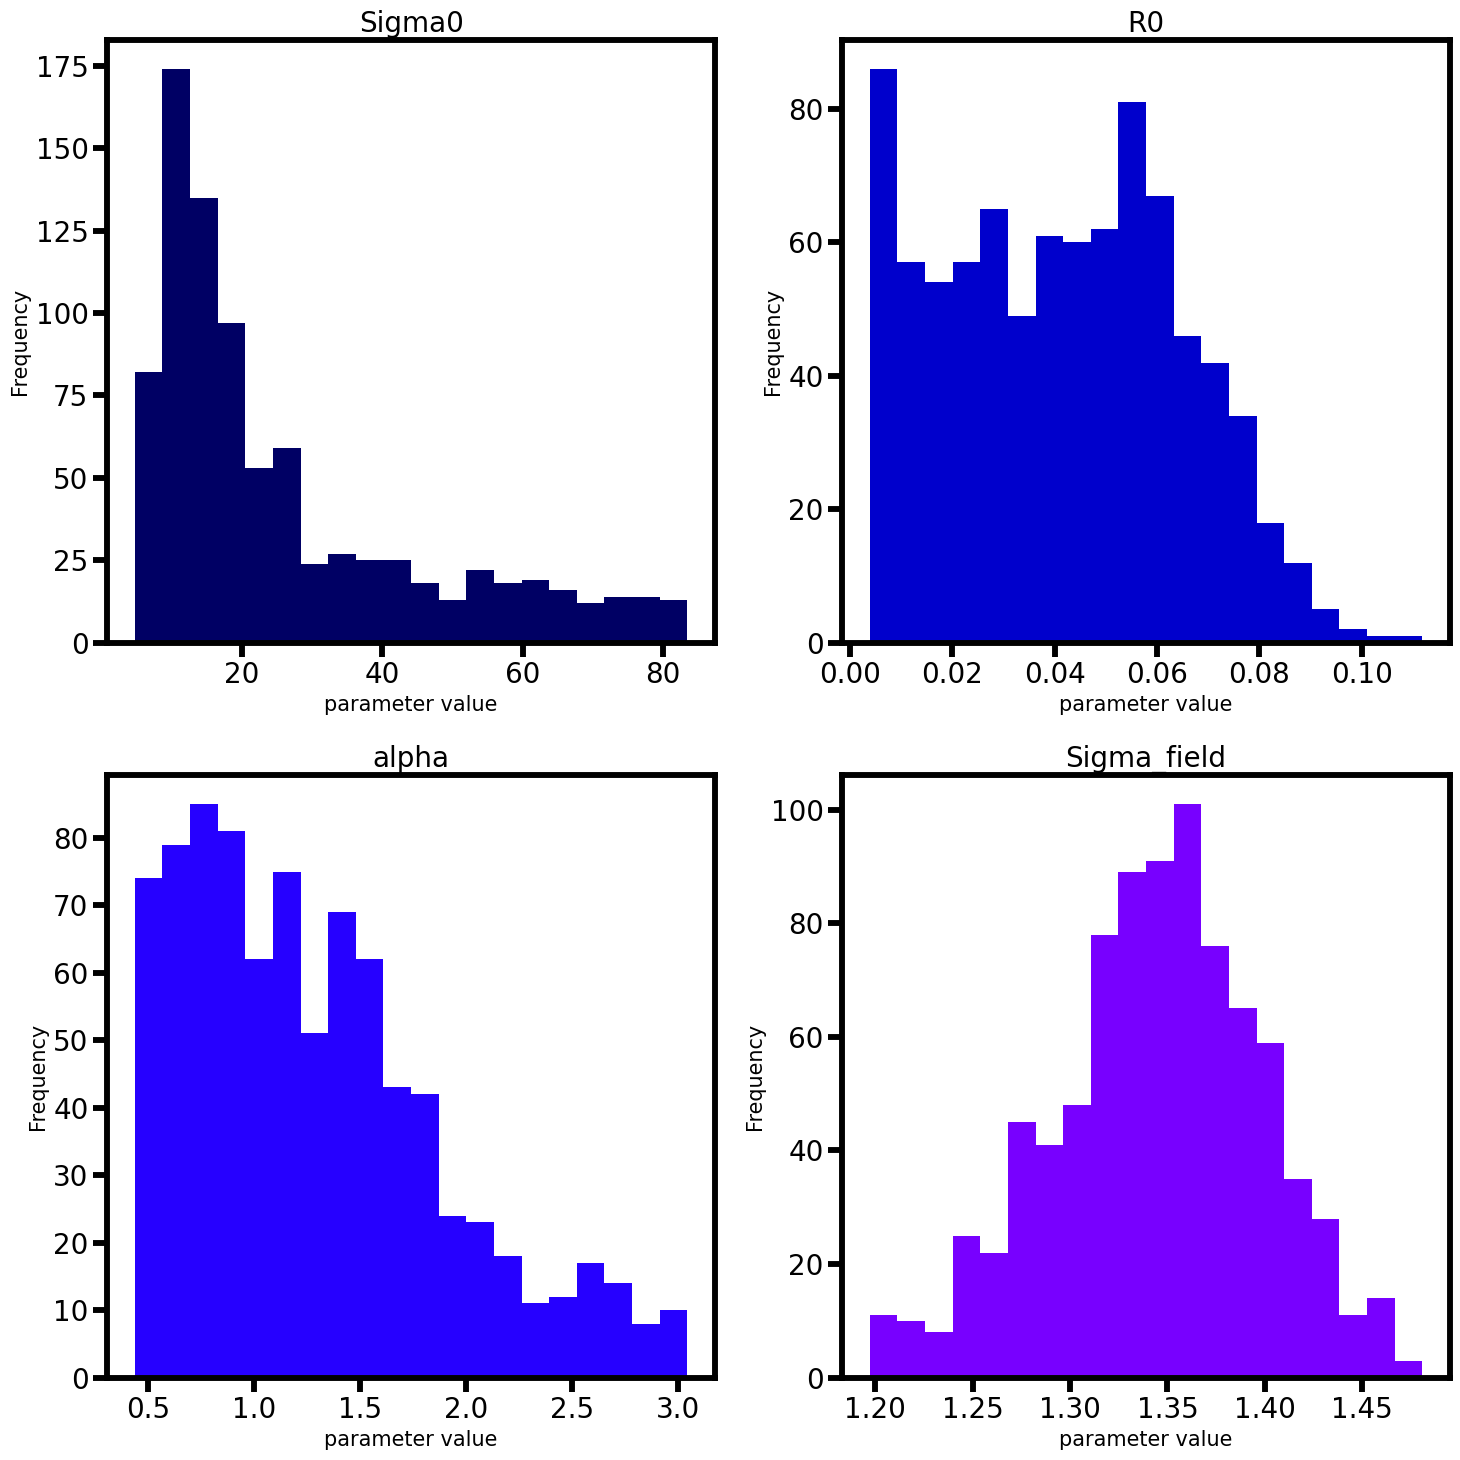

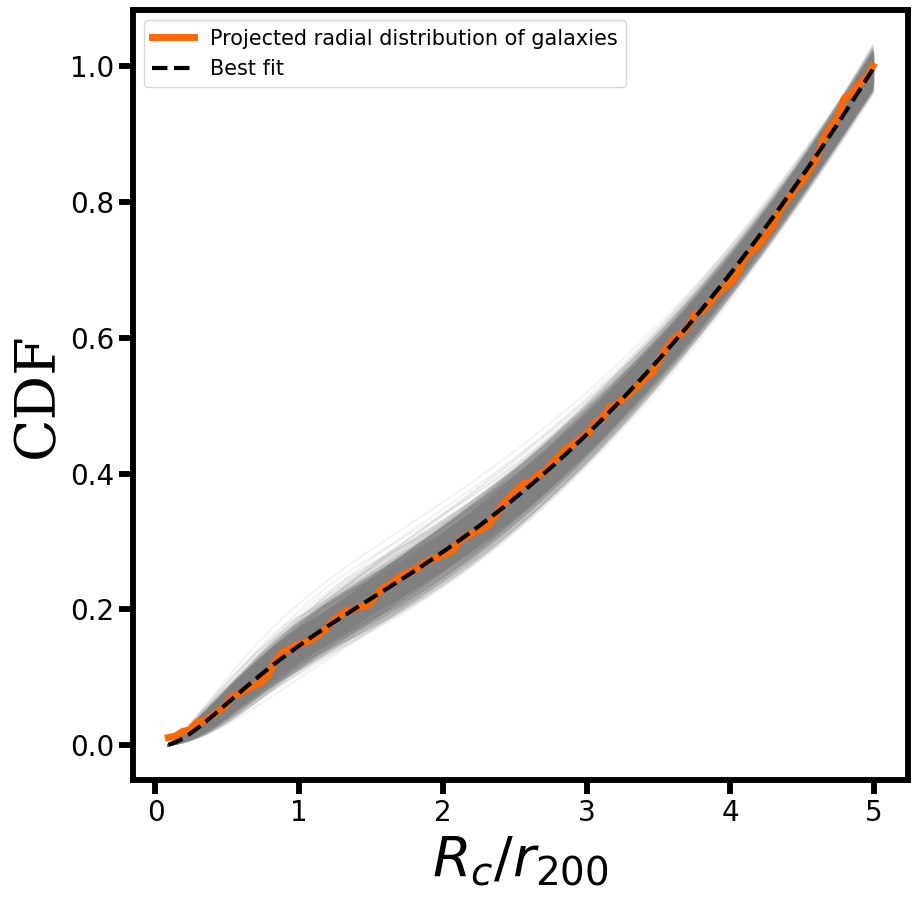

In [11]:
nsteps = 10000
nwalkers = 32
burn_in = 0.2

i_mock_list = []
Sigma0_list = []
R0_list = []
alpha_list = []
Sigma_field_list = []
R0_r200_list = []   


for i_mock in range(49, 50):

    print("COMPUTING FOR MOCK CLUSTER", i_mock)

    t = pd.read_csv("tables/testing-on-mocks/membership-mock-clusters/23-07-2025/cluster-mock_{}_membership.csv".format(i_mock))
    members = t["phot_member"] == 1
    ras = np.array(t["RA"][members]) #deg
    decs = np.array(t["DEC"][members]) #deg
    zp = np.array(t["z_phot_pdfs_mock"][members]) #uso os photo-zs que vem da "clonagem" de galáxias do training set
    zs = np.array(t["z_app"][members]) 


    x0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/ra0_list.npy")[i_mock]
    y0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/dec0_list.npy")[i_mock]
    r200_deg = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_deg_list.npy")[i_mock]
    r200_mpc = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_mpc_list.npy")[i_mock]
    m200 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/m200_list.npy")[i_mock]
    z_cluster = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/z_cluster_list.npy")[i_mock]


    side = min(max(ras) - min(ras), max(decs) - min(decs))
    all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

    
    #Distribuição cumulativa observada
    Rp = clustercentric_distance(ras, decs, x0, y0)
    Hz, Rcz = np.histogram(Rp, bins=100, density=True)
    dR = Rcz[1] - Rcz[0]
    Fz = np.cumsum(Hz)*dR
    R = Rcz[1:]

    #======================================
    #GUESSING PARAMETERS WITH MCMC
    #======================================
    init = [1, r200_deg/2, 1, 0.5]
    pos = init + 1e-4 * np.random.randn(nwalkers, len(init))

    sampler = run_mcmc(nsteps, 
                        pos,
                        log_probability, 
                        args=(R, dR, Fz), 
                        moves=emcee.moves.StretchMove(),
                        multi_process=False)

    labels = [r"$\Sigma_0$", r"$R_0$", r"$\alpha$", r"$\Sigma_{field}$"]

    samples = sampler.get_chain()

    #flat = flatten the chains across the ensample
    #discard = discard the burn_in phase
    #thin = "thins" the sample every N iterations (for instance 15)
    flat_samples = sampler.get_chain(discard=int(nsteps*burn_in), thin=15, flat=True)
    means = np.mean(flat_samples, axis=0)

    fig, axes = plt.subplots(4, figsize=(10, 15), sharex=True)

    # Styling
    rcParams["font.size"] = 10
    rcParams["axes.labelsize"] = 10
    rcParams["xtick.labelsize"] = 10
    rcParams["ytick.labelsize"] = 10
    for i in range(np.shape(pos)[1]):
        ax = axes[i]
        ax.plot(samples[:, :, i], "blue", alpha=0.3)
        ax.axhline(np.median(samples[int(burn_in*nsteps):, :, i]), color="red", lw=2.0)
        ax.set_xlim(0, len(samples))
        ax.set_ylabel(labels[i], fontdict=font)
        ax.yaxis.set_label_coords(-0.1, 0.5)

        print(np.median(samples[int(burn_in*nsteps):, :, i]))

    axes[-1].set_xlabel("step number", fontdict=font);

    plt.savefig("../figures/elliptical_profiles/boostrap_results/Sersic/trace_plot_mcmc_mock{}.png".format(i_mock),
                                         dpi='figure', format='png')


    initial_guess = np.array([np.median(samples[int(burn_in*nsteps):, :, i]) for i in range(0, 4)])

    #======================================
    #MINIMIZING CHI2 TO FIND BEST FIT
    #======================================
    fit = fit_cumulative(R, dR, Fz, init=initial_guess)

    print("Fitted parameters:")
    for p_value, p_name in zip(fit.x, ["Sigma0", "R0", "alpha", "Sigma_field"]):
        print(p_name + " =", p_value)

    print("R0/r200 = {:.3f}".format(fit.x[1]/r200_deg))

    cum_dens = Sersic_density(R, dR, fit.x)

    # Run bootstrap
    t0 = time.time()
    nboot = 1000
    boot_results = bootstrap_fit(all_galaxies, init=fit.x, B=nboot)
    print("Bootstrap time taken:", time.time() - t0)
    boot_results.to_csv("tables/testing-on-mocks/bootstrap_results/Sersic/boot_results_mock{}.csv".format(i_mock), index=False)


    # Remove outliers
    z = boot_results
    for col in boot_results.columns:
        Q1 = boot_results[col].quantile(0.25)
        Q3 = boot_results[col].quantile(0.75)
        IQR = Q3 - Q1
        z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
        print("Remaining samples after outlier removal:", len(z))
    boot_results_outliers_removed = z
    boot_results_outliers_removed.to_csv("tables/testing-on-mocks/bootstrap_results/Sersic/boot_results_outliers_removed_mock{}.csv".format(i_mock), index=False)


    # Plot parameter distributions
    rcParams["font.size"] = 20
    rcParams["axes.labelsize"] = 20
    rcParams["xtick.labelsize"] = 20
    rcParams["ytick.labelsize"] = 20
    plt.figure(figsize=(15, 15))
    for i, col in enumerate(boot_results_outliers_removed.columns[:-1]):  # exclude chi2
        plt.subplot(2, 2, i+1)
        plt.hist(boot_results_outliers_removed[col], bins=20, color=colors3[i])
        plt.title(col, fontsize=20)
        plt.xlabel("parameter value", fontsize=15)
        plt.ylabel("Frequency", fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/elliptical_profiles/boostrap_results/Sersic/boostrap_parameter_distribution_mock{}.png".format(i_mock), dpi='figure', format='png')


    # Plot cumulative density fit and bootstrap results
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)   
    ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
    ax.set_ylabel("CDF", fontdict=font)

    for _, row in boot_results_outliers_removed.iterrows():
        params = row[:4].values
        cum_model = Sersic_density(R, dR, params)
        ax.plot(R/r200_deg, cum_model, color="gray", alpha=0.1)

    ax.plot(R/r200_deg, Fz, lw=5.0, c="#ff6700", label="Projected radial distribution of galaxies", alpha=1.0)
    ax.plot(R/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c="k")

    ax.legend(fontsize=15)
    plt.savefig("../figures/elliptical_profiles/boostrap_results/Sersic/cumulative_density_fit_mock{}.png".format(i_mock), dpi='figure', format='png')


    #SAVING BEST FIT PARAMETERS
    i_mock_list.append(i_mock)
    Sigma0_list.append(fit.x[0])
    R0_list.append(fit.x[1])
    alpha_list.append(fit.x[2])
    Sigma_field_list.append(fit.x[3])
    R0_r200_list.append(fit.x[1]/r200_deg)  
    
    np.save("tables/testing-on-mocks/bootstrap_results/Sersic/i_mock_list", i_mock_list)
    np.save("tables/testing-on-mocks/bootstrap_results/Sersic/Sigma0_list", Sigma0_list)
    np.save("tables/testing-on-mocks/bootstrap_results/Sersic/R0_list", R0_list)
    np.save("tables/testing-on-mocks/bootstrap_results/Sersic/alpha_list", alpha_list)
    np.save("tables/testing-on-mocks/bootstrap_results/Sersic/Sigma_field_list", Sigma_field_list)
    np.save("tables/testing-on-mocks/bootstrap_results/Sersic/R0_r200_list", R0_r200_list)
    